In [1]:
!pip install -q opencv-python matplotlib

In [2]:
# Level 1 - done in the previous Robotics demo previous section
# Its purpose is not sophistication
# It teaches the architecture of Physical AI

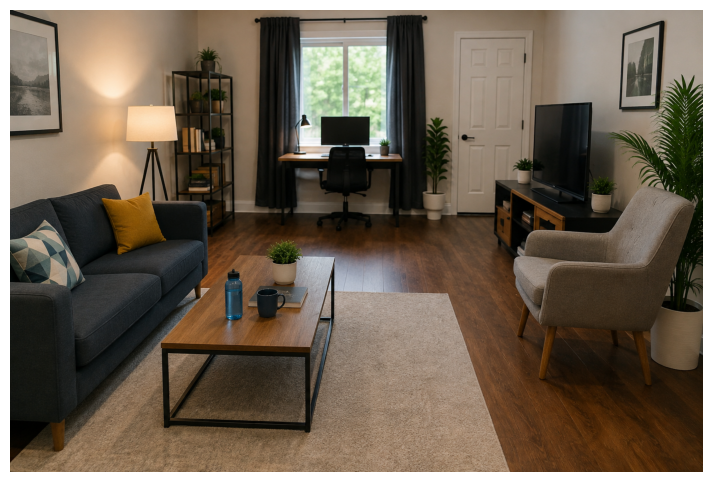

In [4]:
# Level 2 — Give the robot vision with OpenCV

# Now replace the artificial obstacle information with an image.
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("/content/sample_data/room.jpg")

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10,6))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

In [5]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.3 MB/s eta 0:00:00


In [6]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.



image 1/1 /content/sample_data/room.jpg: 448x640 1 bottle, 1 chair, 1 couch, 9 potted plants, 2 tvs, 400.7ms
Speed: 26.7ms preprocess, 400.7ms inference, 33.1ms postprocess per image at shape (1, 3, 448, 640)


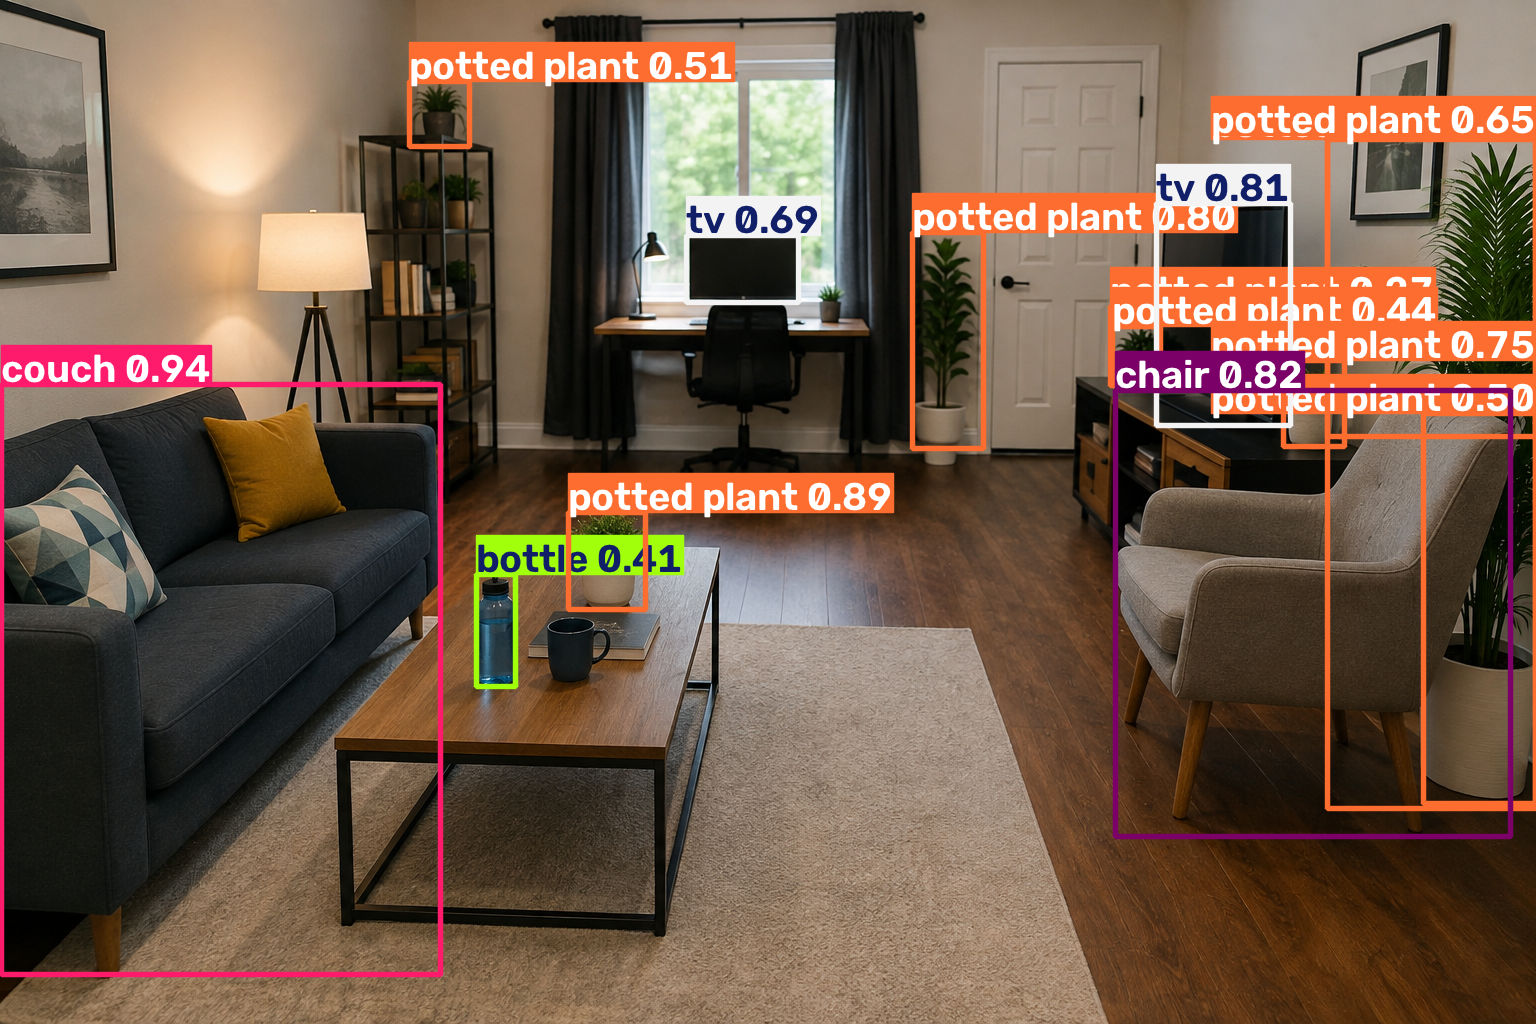

In [7]:
results = model(
    "/content/sample_data/room.jpg"
)

results[0].show()

In [8]:
for box in results[0].boxes:

    class_id = int(box.cls[0])

    class_name = model.names[class_id]

    confidence = float(box.conf[0])

    print(
        class_name,
        round(confidence, 2)
    )

couch 0.94
potted plant 0.89
chair 0.82
tv 0.81
potted plant 0.8
potted plant 0.75
tv 0.69
potted plant 0.65
potted plant 0.51
potted plant 0.5
potted plant 0.44
bottle 0.41
potted plant 0.36
potted plant 0.27


In [9]:
# Level 4 — Connect vision to action
# Suppose our robot receives:
# Find the bottle.
# We can convert YOLO detections into robot decisions.

detected_objects = []

for box in results[0].boxes:

    class_id = int(box.cls[0])

    name = model.names[class_id]

    detected_objects.append(name)

print(detected_objects)

['couch', 'potted plant', 'chair', 'tv', 'potted plant', 'potted plant', 'tv', 'potted plant', 'potted plant', 'potted plant', 'potted plant', 'bottle', 'potted plant', 'potted plant']


In [10]:
# Level 4 — Connect vision to action

target_object = "bottle"

if target_object in detected_objects:

    print("Bottle detected")
    print("Robot decision: Move toward bottle")

else:

    print("Bottle not found")
    print("Robot decision: Continue searching")

Bottle detected
Robot decision: Move toward bottle


In [11]:
!pip install -q gymnasium stable-baselines3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 5.0 MB/s eta 0:00:00


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Environment created
PPO agent created

Training robot...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training completed
Step: 0 Robot: [1 0] Reward: 1.0
Step: 1 Robot: [2 0] Reward: 1.0
Step: 2 Robot: [3 0] Reward: 1.0
Step: 3 Robot: [4 0] Reward: 1.0
Step: 4 Robot: [5 0] Reward: 1.0
Step: 5 Robot: [6 0] Reward: 1.0
Step: 6 Robot: [6 1] Reward: 1.0
Step: 7 Robot: [6 2] Reward: 1.0
Step: 8 Robot: [6 3] Reward: 1.0
Step: 9 Robot: [6 4] Reward: 1.0
Step: 10 Robot: [6 5] Reward: 1.0
Step: 11 Robot: [6 6] Reward: 1.0
Step: 12 Robot: [6 7] Reward: 1.0
Step: 13 Robot: [6 7] Reward: -1.0
Step: 14 Robot: [6 7] Reward: -1.0
Step: 15 Robot: [6 7] Reward: -1.0
Step: 16 Robot: [6 7] Reward: -1.0
Step: 17 Robot: [6 7] Reward: -1.0
Step: 18 Robot: [6 7] Reward: -1.0
Step: 19 Robot: [6 7] Reward: -1.0
Step: 20 Robot: [6 7] Reward: -1.0
Step: 21 Robot: [6 7] Reward: -1.0
Step: 22 Robot: [6 7] Reward: -1.0
Step: 23 Robot: [6 7] Reward: -1.0
Step: 24 Robot: [6 7] Reward: -1.0
Step: 25 Robot: [6 7] Reward: -1.0
Step: 26 Robot: [6 7] Reward: -1.0
Step: 27 Robot: [6 7] Reward: -1.0
Step: 28 Robot: [6 7] Re

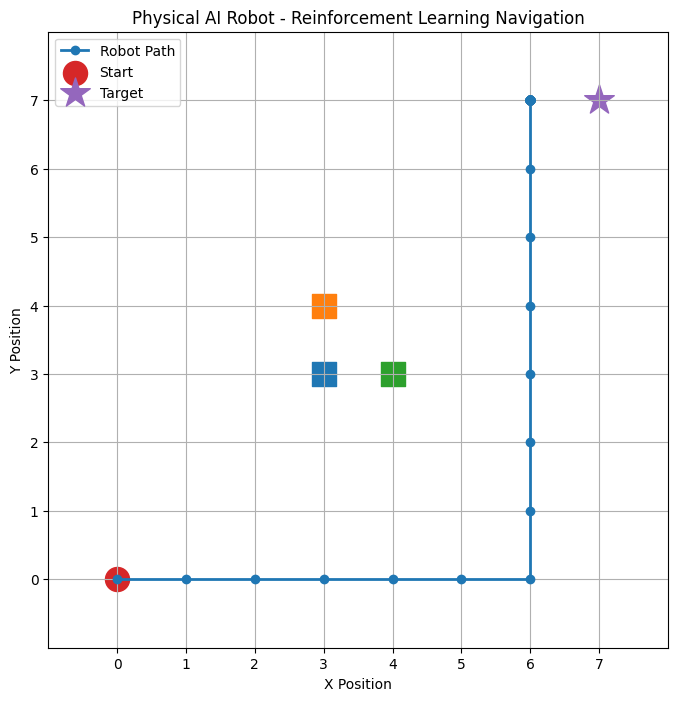


Final robot position: [6 7]
Target position: [7 7]
Target reached: False


In [12]:
# ============================================================
# LEVEL 5 - REINFORCEMENT LEARNING FOR PHYSICAL AI
# Robot learns to navigate toward a target
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import PPO


# ------------------------------------------------------------
# 1. CREATE PHYSICAL AI ENVIRONMENT
# ------------------------------------------------------------

class GridRobotEnv(gym.Env):

    def __init__(self, size=8):

        super().__init__()

        self.size = size

        # ------------------------------------
        # Robot actions
        # ------------------------------------
        # 0 = UP
        # 1 = DOWN
        # 2 = LEFT
        # 3 = RIGHT

        self.action_space = spaces.Discrete(4)

        # Observation:
        #
        # robot_x
        # robot_y
        # target_x
        # target_y

        self.observation_space = spaces.Box(
            low=0,
            high=size - 1,
            shape=(4,),
            dtype=np.float32
        )

        # Target location

        self.target = np.array(
            [size - 1, size - 1],
            dtype=np.int32
        )

        # Obstacles

        self.obstacles = {
            (3, 3),
            (3, 4),
            (4, 3)
        }


    # --------------------------------------------------------
    # CREATE OBSERVATION
    # --------------------------------------------------------

    def get_observation(self):

        return np.array(
            [
                self.robot[0],
                self.robot[1],
                self.target[0],
                self.target[1]
            ],
            dtype=np.float32
        )


    # --------------------------------------------------------
    # RESET ENVIRONMENT
    # --------------------------------------------------------

    def reset(self, seed=None, options=None):

        super().reset(seed=seed)

        self.robot = np.array(
            [0, 0],
            dtype=np.int32
        )

        return self.get_observation(), {}


    # --------------------------------------------------------
    # ROBOT ACTION
    # --------------------------------------------------------

    def step(self, action):

        moves = {

            0: np.array([0, 1]),    # UP

            1: np.array([0, -1]),   # DOWN

            2: np.array([-1, 0]),   # LEFT

            3: np.array([1, 0])     # RIGHT
        }

        old_distance = np.linalg.norm(
            self.target - self.robot
        )

        # Calculate next position

        candidate = (
            self.robot
            + moves[int(action)]
        )

        # Prevent robot leaving environment

        candidate = np.clip(
            candidate,
            0,
            self.size - 1
        )

        # Default movement cost

        reward = -1.0


        # ----------------------------------------------------
        # COLLISION CHECK
        # ----------------------------------------------------

        if tuple(candidate) in self.obstacles:

            # Punish hitting obstacle

            reward -= 10

        else:

            self.robot = candidate


        # ----------------------------------------------------
        # DISTANCE REWARD
        # ----------------------------------------------------

        new_distance = np.linalg.norm(
            self.target - self.robot
        )

        # Reward moving closer

        if new_distance < old_distance:

            reward += 2


        # ----------------------------------------------------
        # TARGET CHECK
        # ----------------------------------------------------

        reached_target = np.array_equal(
            self.robot,
            self.target
        )

        if reached_target:

            reward += 100


        terminated = reached_target

        truncated = False


        return (
            self.get_observation(),
            reward,
            terminated,
            truncated,
            {}
        )


# ============================================================
# 2. CREATE ENVIRONMENT
# ============================================================

env = GridRobotEnv(size=8)

print("Environment created")


# ============================================================
# 3. CREATE REINFORCEMENT LEARNING AGENT
# ============================================================

model = PPO(
    "MlpPolicy",
    env,
    verbose=0
)

print("PPO agent created")


# ============================================================
# 4. TRAIN ROBOT
# ============================================================

print("\nTraining robot...")

model.learn(
    total_timesteps=20000
)

print("Training completed")


# ============================================================
# 5. TEST TRAINED ROBOT
# ============================================================

observation, info = env.reset()

trajectory = [
    env.robot.copy()
]


for step in range(100):

    action, _ = model.predict(
        observation,
        deterministic=True
    )

    observation, reward, terminated, truncated, info = env.step(
        action
    )

    trajectory.append(
        env.robot.copy()
    )

    print(
        "Step:",
        step,
        "Robot:",
        env.robot,
        "Reward:",
        reward
    )

    if terminated:

        print("\nTARGET REACHED!")

        break


# ============================================================
# 6. VISUALIZE LEARNED PATH
# ============================================================

trajectory = np.array(
    trajectory
)


plt.figure(
    figsize=(8, 8)
)


# Robot trajectory

plt.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    marker="o",
    linewidth=2,
    label="Robot Path"
)


# Obstacles

for obstacle in env.obstacles:

    plt.scatter(
        obstacle[0],
        obstacle[1],
        marker="s",
        s=300
    )


# Start

plt.scatter(
    0,
    0,
    s=300,
    label="Start"
)


# Target

plt.scatter(
    env.target[0],
    env.target[1],
    marker="*",
    s=500,
    label="Target"
)


plt.xlim(
    -1,
    env.size
)

plt.ylim(
    -1,
    env.size
)

plt.xticks(
    range(env.size)
)

plt.yticks(
    range(env.size)
)

plt.grid(True)

plt.legend()

plt.title(
    "Physical AI Robot - Reinforcement Learning Navigation"
)

plt.xlabel(
    "X Position"
)

plt.ylabel(
    "Y Position"
)

plt.show()


# ============================================================
# 7. FINAL RESULT
# ============================================================

print("\nFinal robot position:", env.robot)

print("Target position:", env.target)

print(
    "Target reached:",
    np.array_equal(
        env.robot,
        env.target
    )
)

In [13]:
!pip install -q google-genai

In [14]:
import os
from google import genai
from google.colab import userdata

#API_KEY = put the new api key here created latest
api_key = userdata.get("GOOGLE_API_KEY")
client = genai.Client(api_key=api_key)
os.environ["GOOGLE_API_KEY"] = api_key
#import os
#from getpass import getpass

#os.environ["GOOGLE_API_KEY"] = getpass("Enter Gemini API key: ")

In [15]:
# Level 6 is largely independent of the reinforcement-learning env
# and model. It introduces a new component:
# Gemini as the high-level reasoning/task-planning layer.

instruction = """
You are the high-level planner for a mobile service robot.

User command:

Find the bottle,
move toward it,
pick it up,
find the person,
bring the bottle to the person,
and release it.

Create a concise numbered robot action plan.
"""

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=instruction
)

print(response.text)

Robot Action Plan:

1.  Locate bottle.
2.  Navigate to bottle.
3.  Grasp bottle.
4.  Locate person.
5.  Navigate to person.
6.  Release bottle.


In [16]:
# Level 7 — YOLO + Gemini: Vision-Language Physical AI Agent
# This level combines:
# Camera/Image → YOLO → detected objects → Gemini → next robot action
# Run this only after you have already executed the earlier
# YOLO and Gemini setup cells.

# ============================================================
# LEVEL 7
# YOLO + GEMINI PHYSICAL AI AGENT
# ============================================================

# Assumptions:
# 1. 'detected_objects' already exists from YOLO
# 2. 'client' already exists from Gemini setup

# Example:
# detected_objects = ["person", "chair", "bottle", "table"]

world_state = sorted(set(detected_objects))

goal = "Bring the bottle to the person."

print("Current world state:")
print(world_state)

print("\nGoal:")
print(goal)


# ------------------------------------------------------------
# CREATE PROMPT FOR GEMINI
# ------------------------------------------------------------

prompt = f"""
You are controlling a service robot.

Current objects visible in the environment:

{world_state}

The robot's goal is:

{goal}

Choose exactly ONE next high-level robot action
from the following list:

SEARCH
MOVE_TO_BOTTLE
GRASP_BOTTLE
MOVE_TO_PERSON
RELEASE_BOTTLE
STOP

Rules:

1. If the bottle is not visible, choose SEARCH.
2. If the bottle is visible but not yet reached, choose MOVE_TO_BOTTLE.
3. If the robot is already near the bottle, choose GRASP_BOTTLE.
4. After grasping the bottle, choose MOVE_TO_PERSON.
5. When near the person, choose RELEASE_BOTTLE.
6. When the task is complete, choose STOP.

Return only the action name.
Do not give explanations.
"""


# ------------------------------------------------------------
# ASK GEMINI
# ------------------------------------------------------------

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=prompt
)

next_action = response.text.strip()

print("\nGemini selected action:")
print(next_action)

Current world state:
['bottle', 'chair', 'couch', 'potted plant', 'tv']

Goal:
Bring the bottle to the person.

Gemini selected action:
MOVE_TO_BOTTLE


In [17]:
# ============================================================
# LEVEL 8
# PHYSICAL AI AGENT WITH MEMORY
# ============================================================

# Assumptions:
# 1. 'client' exists
# 2. 'detected_objects' exists

memory = []

goal = "Bring the bottle to the person."

world_state = sorted(set(detected_objects))


# ------------------------------------------------------------
# MEMORY FUNCTION
# ------------------------------------------------------------

def remember(event):
    memory.append(event)


# ------------------------------------------------------------
# AGENT DECISION FUNCTION
# ------------------------------------------------------------

def choose_next_action(objects, goal, memory):

    prompt = f"""
You control a simulated Physical AI service robot.

CURRENT VISIBLE OBJECTS:

{objects}

GOAL:

{goal}

MEMORY OF PREVIOUS EVENTS:

{memory}

Choose exactly ONE next high-level action:

SEARCH
MOVE_TO_BOTTLE
GRASP_BOTTLE
MOVE_TO_PERSON
RELEASE_BOTTLE
STOP

Return only the action name.
Do not explain.
"""

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    return response.text.strip()


# ------------------------------------------------------------
# SIMULATED ROBOT STATE
# ------------------------------------------------------------

robot_near_bottle = False
holding_bottle = False
robot_near_person = False
task_complete = False


# ------------------------------------------------------------
# CLOSED AGENT LOOP
# ------------------------------------------------------------

for step in range(10):

    print("\n==============================")
    print("STEP:", step + 1)
    print("==============================")

    # Build richer state information

    state_description = {
        "visible_objects": world_state,
        "robot_near_bottle": robot_near_bottle,
        "holding_bottle": holding_bottle,
        "robot_near_person": robot_near_person,
        "task_complete": task_complete
    }

    action = choose_next_action(
        state_description,
        goal,
        memory
    )

    print("Selected action:", action)


    # --------------------------------------------------------
    # SIMULATE ACTION EXECUTION
    # --------------------------------------------------------

    if action == "SEARCH":

        remember(
            "Robot searched the environment."
        )

        print("Robot is searching...")


    elif action == "MOVE_TO_BOTTLE":

        if "bottle" in world_state:

            robot_near_bottle = True

            remember(
                "Robot moved close to the bottle."
            )

            print(
                "Robot moved toward the bottle."
            )

        else:

            remember(
                "Bottle was not visible."
            )


    elif action == "GRASP_BOTTLE":

        if robot_near_bottle:

            holding_bottle = True

            remember(
                "Robot successfully grasped the bottle."
            )

            print(
                "Robot grasped the bottle."
            )

        else:

            remember(
                "Robot tried to grasp the bottle "
                "but was not close enough."
            )


    elif action == "MOVE_TO_PERSON":

        if holding_bottle and "person" in world_state:

            robot_near_person = True

            remember(
                "Robot moved toward the person "
                "while holding the bottle."
            )

            print(
                "Robot moved toward the person."
            )

        else:

            remember(
                "Robot could not move toward "
                "the person with the bottle."
            )


    elif action == "RELEASE_BOTTLE":

        if holding_bottle and robot_near_person:

            holding_bottle = False
            task_complete = True

            remember(
                "Robot released the bottle "
                "near the person."
            )

            print(
                "Robot released the bottle."
            )

        else:

            remember(
                "Robot attempted release "
                "before reaching the person."
            )


    elif action == "STOP":

        print("Robot stopped.")

        break


    else:

        print(
            "Unknown action returned by Gemini:",
            action
        )

        remember(
            f"Unknown action received: {action}"
        )


    # --------------------------------------------------------
    # CHECK TASK COMPLETION
    # --------------------------------------------------------

    if task_complete:

        print("\nTASK COMPLETED SUCCESSFULLY!")

        remember(
            "Overall task completed successfully."
        )

        break


# ------------------------------------------------------------
# DISPLAY MEMORY
# ------------------------------------------------------------

print("\n\nROBOT MEMORY")
print("============")

for i, event in enumerate(memory, start=1):

    print(
        f"{i}. {event}"
    )


STEP: 1
Selected action: MOVE_TO_BOTTLE
Robot moved toward the bottle.

STEP: 2
Selected action: GRASP_BOTTLE
Robot grasped the bottle.

STEP: 3
Selected action: MOVE_TO_PERSON

STEP: 4
Selected action: SEARCH
Robot is searching...

STEP: 5
Selected action: SEARCH
Robot is searching...

STEP: 6
Selected action: SEARCH
Robot is searching...

STEP: 7
Selected action: MOVE_TO_PERSON

STEP: 8
Selected action: RELEASE_BOTTLE

STEP: 9
Selected action: SEARCH
Robot is searching...

STEP: 10
Selected action: SEARCH
Robot is searching...


ROBOT MEMORY
1. Robot moved close to the bottle.
2. Robot successfully grasped the bottle.
3. Robot could not move toward the person with the bottle.
4. Robot searched the environment.
5. Robot searched the environment.
6. Robot searched the environment.
7. Robot could not move toward the person with the bottle.
8. Robot attempted release before reaching the person.
9. Robot searched the environment.
10. Robot searched the environment.


In [18]:
# Colab-safe ROS2 concept simulation

# This code does not require ROS2 installation. It simulates the
# publish/subscribe architecture so participants understand ROS2 first.

# ============================================================
# LEVEL 9
# ROS2 CONCEPT SIMULATION IN GOOGLE COLAB
# ============================================================

import time


# ------------------------------------------------------------
# SIMPLE ROS2-LIKE MESSAGE
# ------------------------------------------------------------

class Twist:

    def __init__(self):

        self.linear_x = 0.0
        self.angular_z = 0.0


# ------------------------------------------------------------
# SIMULATED ROS2 TOPIC
# ------------------------------------------------------------

class Topic:

    def __init__(self, name):

        self.name = name
        self.subscribers = []


    def subscribe(self, callback):

        self.subscribers.append(callback)


    def publish(self, message):

        print(
            f"\nPublishing message on topic: {self.name}"
        )

        for callback in self.subscribers:

            callback(message)


# ------------------------------------------------------------
# ROBOT MOTOR CONTROLLER
# ------------------------------------------------------------

class RobotMotorController:

    def velocity_callback(self, message):

        print(
            "Motor Controller received:"
        )

        print(
            "Linear velocity:",
            message.linear_x
        )

        print(
            "Angular velocity:",
            message.angular_z
        )


        if message.linear_x > 0:

            print(
                "ACTION: Robot moving FORWARD"
            )

        elif message.linear_x < 0:

            print(
                "ACTION: Robot moving BACKWARD"
            )


        if message.angular_z > 0:

            print(
                "ACTION: Robot turning LEFT"
            )

        elif message.angular_z < 0:

            print(
                "ACTION: Robot turning RIGHT"
            )


# ------------------------------------------------------------
# CREATE ROS2-LIKE TOPIC
# ------------------------------------------------------------

cmd_vel_topic = Topic(
    "/cmd_vel"
)


# ------------------------------------------------------------
# CREATE ROBOT CONTROLLER
# ------------------------------------------------------------

motor_controller = RobotMotorController()


# Subscribe controller to /cmd_vel

cmd_vel_topic.subscribe(
    motor_controller.velocity_callback
)


# ------------------------------------------------------------
# HIGH-LEVEL AGENT COMMAND
# ------------------------------------------------------------

agent_action = "MOVE_FORWARD"


# ------------------------------------------------------------
# TRANSLATE AI ACTION INTO ROBOT MESSAGE
# ------------------------------------------------------------

velocity_command = Twist()


if agent_action == "MOVE_FORWARD":

    velocity_command.linear_x = 0.5


elif agent_action == "TURN_LEFT":

    velocity_command.angular_z = 0.5


elif agent_action == "TURN_RIGHT":

    velocity_command.angular_z = -0.5


elif agent_action == "STOP":

    velocity_command.linear_x = 0.0

    velocity_command.angular_z = 0.0


# ------------------------------------------------------------
# PUBLISH COMMAND
# ------------------------------------------------------------

print(
    "Agent decision:",
    agent_action
)

cmd_vel_topic.publish(
    velocity_command
)

Agent decision: MOVE_FORWARD

Publishing message on topic: /cmd_vel
Motor Controller received:
Linear velocity: 0.5
Angular velocity: 0.0
ACTION: Robot moving FORWARD


In [ ]:
# do not run this code on colab
#Level 9B — Actual ROS2 Python code

# This should be run in a proper ROS2 Ubuntu environment rather
# than ordinary Colab.

import rclpy

from rclpy.node import Node

from geometry_msgs.msg import Twist


class RobotController(Node):

    def __init__(self):

        super().__init__(
            "physical_ai_controller"
        )

        self.publisher = self.create_publisher(
            Twist,
            "/cmd_vel",
            10
        )


    def execute_action(
        self,
        action
    ):

        msg = Twist()


        if action == "MOVE_FORWARD":

            msg.linear.x = 0.5


        elif action == "MOVE_BACKWARD":

            msg.linear.x = -0.5


        elif action == "TURN_LEFT":

            msg.angular.z = 0.5


        elif action == "TURN_RIGHT":

            msg.angular.z = -0.5


        elif action == "STOP":

            msg.linear.x = 0.0

            msg.angular.z = 0.0


        self.publisher.publish(
            msg
        )

        self.get_logger().info(
            f"Executed action: {action}"
        )


# ------------------------------------------------------------
# START ROS2
# ------------------------------------------------------------

rclpy.init()


controller = RobotController()


agent_action = "MOVE_FORWARD"


controller.execute_action(
    agent_action
)


rclpy.spin_once(
    controller,
    timeout_sec=1.0
)


controller.destroy_node()


rclpy.shutdown()

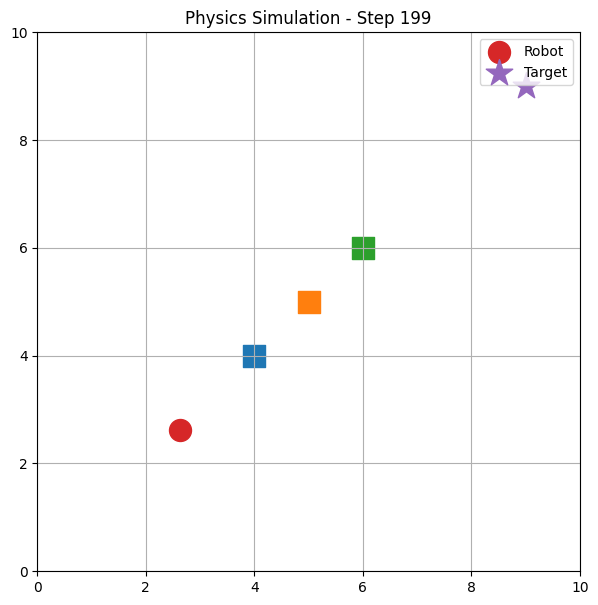

In [20]:
# Level 10A — Colab physics simulation

# For Colab, we can simulate the same idea using Python physics
# rather than launching Gazebo GUI.

# ============================================================
# LEVEL 10
# SIMPLE PHYSICS-BASED ROBOT SIMULATION
# COLAB VERSION
# ============================================================

import numpy as np

import matplotlib.pyplot as plt

from IPython.display import clear_output

import time


# ------------------------------------------------------------
# PHYSICAL PARAMETERS
# ------------------------------------------------------------

dt = 0.1


robot_position = np.array(
    [1.0, 1.0]
)


robot_velocity = np.array(
    [0.0, 0.0]
)


target = np.array(
    [9.0, 9.0]
)


MAX_SPEED = 1.0


# ------------------------------------------------------------
# OBSTACLES
# ------------------------------------------------------------

obstacles = [

    np.array([4.0, 4.0]),

    np.array([5.0, 5.0]),

    np.array([6.0, 6.0])

]


# ------------------------------------------------------------
# SENSOR
# ------------------------------------------------------------

def lidar_sensor(
    robot_position,
    range_limit=2.0
):

    detected = []

    for obstacle in obstacles:

        distance = np.linalg.norm(
            obstacle
            - robot_position
        )

        if distance <= range_limit:

            detected.append(
                obstacle
            )

    return detected


# ------------------------------------------------------------
# CONTROLLER
# ------------------------------------------------------------

def compute_velocity(
    robot_position
):

    direction = (
        target
        - robot_position
    )


    distance = np.linalg.norm(
        direction
    )


    if distance < 0.2:

        return np.array(
            [0.0, 0.0]
        )


    direction = (
        direction
        / distance
    )


    return (
        direction
        * MAX_SPEED
    )


# ------------------------------------------------------------
# PHYSICS UPDATE
# ------------------------------------------------------------

def physics_step(
    position,
    velocity
):

    new_position = (
        position
        + velocity
        * dt
    )


    return new_position


# ------------------------------------------------------------
# RUN SIMULATION
# ------------------------------------------------------------

trajectory = []


for step in range(200):


    # SENSE

    detected = lidar_sensor(
        robot_position
    )


    # PLAN

    robot_velocity = compute_velocity(
        robot_position
    )


    # Basic obstacle avoidance

    for obstacle in detected:

        away = (
            robot_position
            - obstacle
        )

        distance = np.linalg.norm(
            away
        )


        if distance > 0:

            robot_velocity += (
                away / distance
            )


    speed = np.linalg.norm(
        robot_velocity
    )


    if speed > MAX_SPEED:

        robot_velocity = (
            robot_velocity
            / speed
            * MAX_SPEED
        )


    # PHYSICS

    robot_position = physics_step(
        robot_position,
        robot_velocity
    )


    trajectory.append(
        robot_position.copy()
    )


    # DISPLAY

    clear_output(
        wait=True
    )


    plt.figure(
        figsize=(7,7)
    )


    for obstacle in obstacles:

        plt.scatter(
            obstacle[0],
            obstacle[1],
            marker="s",
            s=250
        )


    plt.scatter(
        robot_position[0],
        robot_position[1],
        s=250,
        label="Robot"
    )


    plt.scatter(
        target[0],
        target[1],
        marker="*",
        s=400,
        label="Target"
    )


    plt.xlim(
        0,
        10
    )

    plt.ylim(
        0,
        10
    )


    plt.grid(True)

    plt.legend()

    plt.title(
        f"Physics Simulation - Step {step}"
    )

    plt.show()


    if np.linalg.norm(
        target - robot_position
    ) < 0.2:

        print(
            "Target reached!"
        )

        break


    time.sleep(
        0.03
    )

Number of animation frames: 301


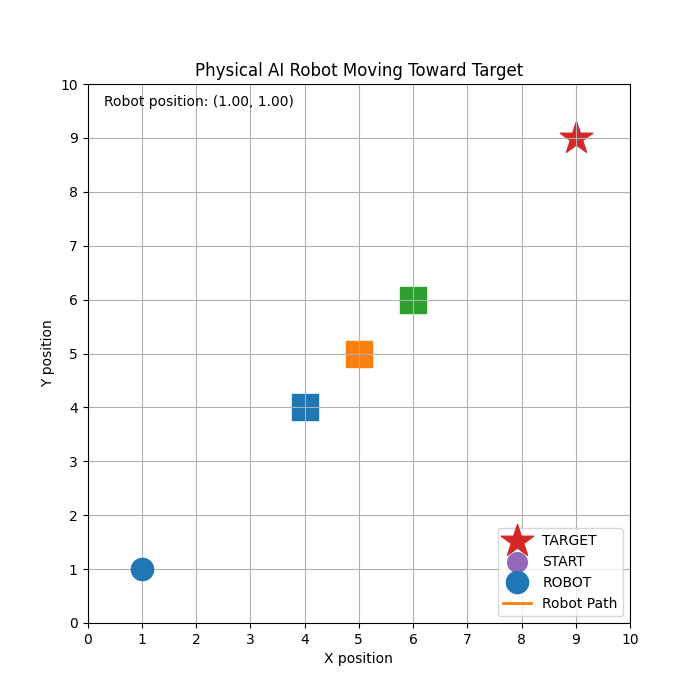

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
# ============================================================
# LEVEL 10A
# PHYSICAL AI ROBOT - VISIBLE MOTION IN GOOGLE COLAB
#
# Sense -> Plan -> Move -> Sense Again
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display


# ============================================================
# 1. ENVIRONMENT
# ============================================================

start_position = np.array(
    [1.0, 1.0]
)

target = np.array(
    [9.0, 9.0]
)

obstacles = [

    np.array([4.0, 4.0]),

    np.array([5.0, 5.0]),

    np.array([6.0, 6.0])

]


# ============================================================
# 2. PHYSICS PARAMETERS
# ============================================================

dt = 0.15

MAX_SPEED = 0.6

SENSOR_RANGE = 2.0


# ============================================================
# 3. SENSOR
# ============================================================

def sense_obstacles(position):

    detected = []

    for obstacle in obstacles:

        distance = np.linalg.norm(
            obstacle - position
        )

        if distance < SENSOR_RANGE:

            detected.append(
                obstacle
            )

    return detected


# ============================================================
# 4. TARGET SEEKING
# ============================================================

def move_toward_target(position):

    direction = (
        target - position
    )

    distance = np.linalg.norm(
        direction
    )

    if distance < 0.15:

        return np.array(
            [0.0, 0.0]
        )

    direction = (
        direction / distance
    )

    velocity = (
        direction * MAX_SPEED
    )

    return velocity


# ============================================================
# 5. OBSTACLE AVOIDANCE
# ============================================================

def avoid_obstacles(
    position,
    velocity
):

    detected = sense_obstacles(
        position
    )

    for obstacle in detected:

        away = (
            position - obstacle
        )

        distance = np.linalg.norm(
            away
        )

        if distance > 0.01:

            # Repulsive direction

            away_direction = (
                away / distance
            )

            # Stronger avoidance
            # when obstacle is close

            strength = (
                1.2 /
                max(distance, 0.2)
            )

            velocity += (
                away_direction
                * strength
            )

    # Limit speed

    speed = np.linalg.norm(
        velocity
    )

    if speed > MAX_SPEED:

        velocity = (
            velocity
            / speed
            * MAX_SPEED
        )

    return velocity


# ============================================================
# 6. GENERATE PHYSICAL MOTION
# ============================================================

robot_position = (
    start_position.copy()
)

trajectory = [

    robot_position.copy()

]


for step in range(300):

    # ----------------------------------------
    # SENSE
    # ----------------------------------------

    detected = sense_obstacles(
        robot_position
    )


    # ----------------------------------------
    # PLAN
    # ----------------------------------------

    velocity = move_toward_target(
        robot_position
    )


    # ----------------------------------------
    # AVOID OBSTACLES
    # ----------------------------------------

    velocity = avoid_obstacles(
        robot_position,
        velocity
    )


    # ----------------------------------------
    # PHYSICAL MOVEMENT
    # ----------------------------------------

    robot_position = (
        robot_position
        + velocity * dt
    )


    trajectory.append(
        robot_position.copy()
    )


    # ----------------------------------------
    # CHECK TARGET
    # ----------------------------------------

    if np.linalg.norm(
        target - robot_position
    ) < 0.2:

        print(
            "Robot reached target at step:",
            step
        )

        break


trajectory = np.array(
    trajectory
)


print(
    "Number of animation frames:",
    len(trajectory)
)


# ============================================================
# 7. CREATE ANIMATION FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)


ax.set_xlim(
    0,
    10
)

ax.set_ylim(
    0,
    10
)


ax.set_xticks(
    range(11)
)

ax.set_yticks(
    range(11)
)


ax.grid(True)


ax.set_xlabel(
    "X position"
)

ax.set_ylabel(
    "Y position"
)


ax.set_title(
    "Physical AI Robot Moving Toward Target"
)


# ============================================================
# 8. DRAW OBSTACLES
# ============================================================

for obstacle in obstacles:

    ax.scatter(
        obstacle[0],
        obstacle[1],
        marker="s",
        s=350
    )


# ============================================================
# 9. DRAW TARGET
# ============================================================

ax.scatter(
    target[0],
    target[1],
    marker="*",
    s=600,
    label="TARGET"
)


# ============================================================
# 10. DRAW START
# ============================================================

ax.scatter(
    start_position[0],
    start_position[1],
    s=200,
    label="START"
)


# ============================================================
# 11. ROBOT OBJECT
# ============================================================

robot_dot, = ax.plot(

    [],

    [],

    marker="o",

    markersize=16,

    linestyle="",

    label="ROBOT"
)


# ============================================================
# 12. TRAJECTORY LINE
# ============================================================

path_line, = ax.plot(

    [],

    [],

    linewidth=2,

    label="Robot Path"
)


# ============================================================
# 13. POSITION DISPLAY
# ============================================================

status_text = ax.text(

    0.3,

    9.6,

    ""

)


ax.legend(
    loc="lower right"
)


# ============================================================
# 14. UPDATE EVERY FRAME
# ============================================================

def animate(frame):

    x = trajectory[
        frame,
        0
    ]

    y = trajectory[
        frame,
        1
    ]


    # Move robot

    robot_dot.set_data(
        [x],
        [y]
    )


    # Show trajectory travelled so far

    path_line.set_data(

        trajectory[
            :frame + 1,
            0
        ],

        trajectory[
            :frame + 1,
            1
        ]

    )


    status_text.set_text(

        "Robot position: "
        f"({x:.2f}, {y:.2f})"

    )


    return (

        robot_dot,

        path_line,

        status_text

    )


# ============================================================
# 15. CREATE ANIMATION
# ============================================================

ani = FuncAnimation(

    fig,

    animate,

    frames=len(
        trajectory
    ),

    interval=200,

    repeat=True

)


# ============================================================
# 16. SAVE AS GIF
# ============================================================

gif_filename = (

    "/content/"
    "physical_ai_robot.gif"

)


ani.save(

    gif_filename,

    writer=PillowWriter(
        fps=5
    )

)


plt.close(fig)


# ============================================================
# 17. SHOW ANIMATED ROBOT
# ============================================================

display(

    Image(
        filename=gif_filename
    )

)

In [21]:
# ============================================================
# LEVEL 11
# ISAAC-SIM-STYLE PHYSICAL AI ARCHITECTURE
# COLAB DEMONSTRATION
# ============================================================


class IsaacWorld:

    def __init__(self):

        self.objects = {

            "robot": {
                "position": [0, 0]
            },

            "bottle": {
                "position": [5, 4]
            },

            "person": {
                "position": [8, 8]
            }

        }


    def get_camera_data(self):

        return [

            "bottle",

            "person",

            "table"

        ]


    def get_robot_position(self):

        return self.objects[
            "robot"
        ]["position"]


    def move_robot(
        self,
        target
    ):

        print(
            f"Isaac controller moving robot toward {target}"
        )


    def grasp(
        self,
        obj
    ):

        print(
            f"Robot grasping {obj}"
        )


    def release(
        self,
        obj
    ):

        print(
            f"Robot releasing {obj}"
        )


# ------------------------------------------------------------
# CREATE DIGITAL TWIN
# ------------------------------------------------------------

world = IsaacWorld()


# ------------------------------------------------------------
# SENSOR PERCEPTION
# ------------------------------------------------------------

camera_objects = (
    world.get_camera_data()
)


print(
    "Camera detected:",
    camera_objects
)


# ------------------------------------------------------------
# HIGH-LEVEL GOAL
# ------------------------------------------------------------

goal = (
    "Bring bottle to person"
)


print(
    "Goal:",
    goal
)


# ------------------------------------------------------------
# TASK EXECUTION
# ------------------------------------------------------------

if "bottle" in camera_objects:

    world.move_robot(
        "bottle"
    )


    world.grasp(
        "bottle"
    )


if "person" in camera_objects:

    world.move_robot(
        "person"
    )


    world.release(
        "bottle"
    )


print(
    "\nPhysical AI task completed."
)

Camera detected: ['bottle', 'person', 'table']
Goal: Bring bottle to person
Isaac controller moving robot toward bottle
Robot grasping bottle
Isaac controller moving robot toward person
Robot releasing bottle

Physical AI task completed.
